In [ ]:
#--> Get historical Data
    #--> volatility from black_scholes
    #--> realized volatility
    #--> Mean Reversion
    #--> VIX Regression

    #--> Indicators
        #--> Volume
        #--> 
#--> Get option Stream
    #--> Volatility curve
#--> Get stock stream
    #--> update volatility curve 

In [23]:
import numpy as np
import pandas as pd
import scipy.stats as stats
import scipy.optimize as opt
from scipy.interpolate import griddata
import matplotlib.pyplot as plt

import nest_asyncio

from datetime import datetime, timedelta

import os
from dotenv import load_dotenv, dotenv_values 
from pathlib import Path

from alpaca.trading.client import TradingClient
from alpaca.data.historical.stock import StockHistoricalDataClient, StockLatestTradeRequest
from alpaca.data.historical.option import OptionHistoricalDataClient

from alpaca.data.timeframe import TimeFrame, TimeFrameUnit
from alpaca.trading.stream import TradingStream
from alpaca.data.live.option import OptionDataStream

from alpaca.trading.requests import MarketOrderRequest
from alpaca.trading.enums import OrderSide, TimeInForce

from alpaca.data.requests import (
    #OptionBarsRequest,
    #OptionTradesRequest,
    OptionLatestQuoteRequest,
    OptionLatestTradeRequest,
    OptionSnapshotRequest,
    OptionChainRequest
)
from alpaca.trading.requests import (
    GetOptionContractsRequest,
    GetAssetsRequest,
    MarketOrderRequest,
    GetOrdersRequest,
    ClosePositionRequest
    #OptionLegRequest
)
from alpaca.trading.enums import (
    AssetStatus,
    #ExerciseStyle,
    OrderSide,
    OrderClass,
    OrderType,
    TimeInForce,
    QueryOrderStatus,
    ContractType
)

from alpaca.common.exceptions import APIError
nest_asyncio.apply()


In [24]:
def get_underlying_price(symbol):
    # Get the latest trade for the underlying stock
    underlying_trade_request = StockLatestTradeRequest(symbol_or_symbols=symbol)
    underlying_trade_response = stock_data_client.get_stock_latest_trade(underlying_trade_request)
    return underlying_trade_response[symbol].price


In [25]:
def get_options(underlying_symbol, expiration_start, expiration_end, option_type, strike_range=0.10):
    
    underlying_price=get_underlying_price(underlying_symbol)
    
    min_strike = str(5*np.ceil(
        (underlying_price * (1 - strike_range))/5)
    )
    max_strike = str(5*np.floor(
        (underlying_price * (1 + strike_range))/5)
    )

    option_contracts_request=GetOptionContractsRequest(
        underlying_symbols=[underlying_symbol],
        status=AssetStatus.ACTIVE,
        strike_price_gte=min_strike,
        strike_price_lte=max_strike,
        expiration_date_gte = expiration_start,                            
        expiration_date_lte = expiration_end, 
        # specify option type (ContractType.CALL or ContractType.PUT)
        type = option_type
    )
    
    option_contracts=trading_client.get_option_contracts(option_contracts_request).option_contracts
    snapshot_request = OptionSnapshotRequest(
        symbol_or_symbols = [s.symbol for s in option_contracts]  
    )
    snapshot=option_data_client.get_option_snapshot(snapshot_request)
    
    option_list=[]

    for s in option_contracts:
        if s.symbol in snapshot:
            j=snapshot[s.symbol]
            option_dict={
                'symbol':j.symbol,
                'implied_volatility':j.implied_volatility,
                'delta':j.greeks.delta if j.greeks is not None else None,
                'gamma':j.greeks.gamma if j.greeks is not None else None,
                'rho':j.greeks.rho if j.greeks is not None else None,
                'theta':j.greeks.theta if j.greeks is not None else None,
                'vega':j.greeks.vega if j.greeks is not None else None,
                'ask':j.latest_quote.ask_price,
                'ask_size':j.latest_quote.ask_size,
                'bid':j.latest_quote.bid_price,
                'bid_size':j.latest_quote.bid_size,
                'mid':(j.latest_quote.ask_price+j.latest_quote.bid_price)/2,
                'id':s.id,
                'underlying_symbol':s.underlying_symbol,
                'expiration':s.expiration_date,
                'strike':s.strike_price,
                'type':s.type,
                'size':s.size
            }
            option_list.append(option_dict)
    
    return pd.DataFrame(option_list)


In [26]:
def time_til_exp(date):
    if type(date) is datetime: 
        pass
    elif type(date) is str:
        date=datetime.strptime(date, DATE_STRING_FORMAT)
    
    delta=date-TODAY.date()
    
    return (delta / pd.Timedelta(days=1))

def black_scholes(S, K, T, sigma, contract_type, r=0.01):

    d_t=time_til_exp(T)/252

    d1 = (np.log(S/K) + (r + (sigma**2)/2)*d_t) / (sigma*np.sqrt(d_t))
    d2 = d1 - sigma*np.sqrt(d_t)

    if contract_type is ContractType.CALL or contract_type == 'CALL':
        sol = (
            S*stats.norm.cdf(d1)
            - K*np.exp(-r*d_t)*stats.norm.cdf(d2)
        )
    elif contract_type is ContractType.PUT or contract_type == 'PUT':
        sol = (
            K*np.exp(-r*d_t)*stats.norm.cdf(-d2)
            -S*stats.norm.cdf(-d1)
        )

    return sol


def C_Greeks(S, K, T, sigma, r=0.01):
    d_t=time_til_exp(T)
    
    d1 = (np.log(S/K) + (r + sigma**2/2)*d_t) / (sigma*np.sqrt(d_t))
    d2 = d1 - sigma*np.sqrt(d_t)
    DRV=stats.norm.pdf(d1)

    Delta=stats.norm.cdf(d1)
    
    Theta=(-r*K*np.exp(-r*d_t)*stats.norm.cdf(d2)
            -(sigma*S/(2*d_t))*DRV)
    
    Gamma=DRV/(sigma*S*np.sqrt(d_t))
    
    Vega=S*np.sqrt(d_t)*DRV
    
    Rho=K*T*np.exp(-r*d_t)*stats.norm.cdf(d2)

    return (Delta,Theta,Gamma,Vega,Rho)

In [27]:
def brent_vol(option_price, S, K, T, contract_type):
    a=0.002
    b=6.0

    if pd.isna(option_price) or option_price <= 0:
        return np.nan

    if pd.isna(S) or pd.isna(K) or pd.isna(T):
        return np.nan

    def price(x):
        bs_price = black_scholes(
            S=S,
            K=K, 
            T=T,
            r=0.02,
            sigma=x, 
            contract_type=contract_type
        )
        
        return bs_price - option_price
        
    try:
        return opt.brentq(price, 1e-6, 5.0)
    except ValueError:
        return np.nan
        
    return opt.brentq(price, a, b)

In [28]:
with open('cashapp.txt') as f:
    cash_app_symbols = [line.strip() for line in f]

In [29]:
load_dotenv()

API_KEY = os.getenv("APCA_API_KEY_ID")
SECRET_KEY = os.getenv("APCA_API_SECRET_KEY")

BASE_URL=None
TRADE_API_WSS = None
DATA_API_URL = None
OPTION_STREAM_DATA_WSS = None

PAPER_TRADE=True

trading_client = TradingClient(
    api_key=API_KEY,
    secret_key=SECRET_KEY,
    paper=PAPER_TRADE  # False for live trading
)

option_data_client = OptionHistoricalDataClient(
    api_key=API_KEY, 
    secret_key=SECRET_KEY, 
    url_override=BASE_URL
)

stock_data_client = StockHistoricalDataClient(
    api_key=API_KEY, 
    secret_key=SECRET_KEY
)


account = trading_client.get_account()

print("Account Status:", account.status)
print("Buying Power:", account.buying_power)
print("Cash:", account.cash)



Account Status: AccountStatus.ACTIVE
Buying Power: 400000
Cash: 100000


In [58]:
#time prep
tte=365
TODAY=datetime.now()
DATE_STRING_FORMAT="%Y-%m-%d"

today_str=TODAY.strftime(DATE_STRING_FORMAT)
exp_start=(TODAY+timedelta(days=1)).strftime(DATE_STRING_FORMAT)
exp_end=(TODAY+timedelta(days=tte)).strftime(DATE_STRING_FORMAT)


#price prep
strike_range=0.10
underlying_symbol=cash_app_symbols[8]

#money prep
#POWER=float(trade_client.get_account().buying_power)
#LIMIT=(0.10)
risk_free_rate=0.01

calls=get_options(
    underlying_symbol=underlying_symbol, 
    expiration_start=exp_start, 
    expiration_end=exp_end, 
    option_type=ContractType.CALL, 
    strike_range=strike_range
)
puts=get_options(
    underlying_symbol=underlying_symbol, 
    expiration_start=exp_start, 
    expiration_end=exp_end, 
    option_type=ContractType.PUT, 
    strike_range=strike_range
)

underlying_price=get_underlying_price(underlying_symbol)


calls['imp_vol']=calls.apply(
    lambda row: brent_vol(
        option_price=row['mid'], 
        S=underlying_price, 
        K=row['strike'], 
        T=row['expiration'],
        contract_type="CALL"
    ),
    axis=1
)

calls['Percent_Error']=(np.abs(calls['imp_vol']-calls['implied_volatility'])/calls['implied_volatility'])*100

print(underlying_symbol)

C:\Users\USER\AppData\Local\Temp\ipykernel_23976\1960057634.py:9: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`).Please use a specific unit instead.
  return (delta / pd.Timedelta(days=1))


SPOT


C:\Users\USER\AppData\Local\Temp\ipykernel_23976\1960057634.py:9: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`).Please use a specific unit instead.
  return (delta / pd.Timedelta(days=1))


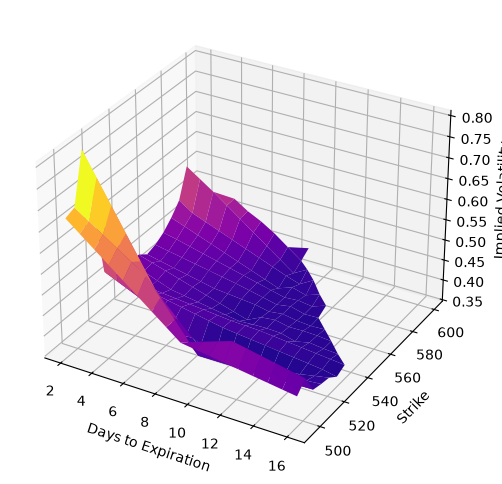

In [60]:
#dataprep
plot_df = calls[['expiration', 'strike', 'imp_vol', 'implied_volatility']].dropna()

interpolation_size=17

X=time_til_exp(plot_df['expiration'])
Y=plot_df['strike']
Z=plot_df['implied_volatility']

xi = np.linspace(X.min(), X.max(), interpolation_size)
yi = np.linspace(Y.min(), Y.max(), interpolation_size)

Xi, Yi = np.meshgrid(xi, yi)

Zi = griddata(
    (X, Y),
    Z,
    (Xi, Yi),
    method='linear'
)

fig=plt.figure(figsize=(12, 6))
ax=fig.add_subplot(111, projection='3d')

ax.plot_surface(
    Xi, 
    Yi, 
    Zi, 
    cmap="plasma"
)

ax.set_xlabel('Days to Expiration')
ax.set_ylabel('Strike')
ax.set_zlabel('Implied Volatility')

plt.show()